# Rejected Approach for Road segmentation: 
## Random Forests

In [1]:
# Basic Imports
import os
import numpy as np
import matplotlib.pyplot as plt
# Image operations
import cv2
# Random Forest
import skimage
from sklearn.ensemble import RandomForestClassifier

from skimage.feature import local_binary_pattern
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.metrics import classification_report

## Data Loading

In [2]:
# Load Datasets
def load_images2(class_folder, img_size=(512, 512), limit=100):
    count = 0
    X = []

    for file in os.listdir(class_folder):
        if count >= limit:
            break
        img_path = os.path.join(class_folder, file)

        # Read image (BGR)
        img = cv2.imread(img_path) 

        if img is None:
            continue  # skip corrupted files

        img = cv2.resize(img, img_size) # Resizing led to worse quality images with fewer keypoints

        X.append(img)
        count += 1

    return np.array(X)

In [3]:
train_folder = "Datasets/road/train"
test_folder = "Datasets/road/test"

train_img = []
train_label = []

image_files = sorted([f for f in os.listdir(train_folder) if f.endswith('_sat.jpg')])
mask_files = sorted([f for f in os.listdir(train_folder) if f.endswith('_mask.png')])

LIMIT = 550 
IMG_SIZE = (512, 512)

for img_file, mask_file in zip(image_files[:LIMIT], mask_files[:LIMIT]):
    img = cv2.imread(os.path.join(train_folder, img_file))
    mask = cv2.imread(os.path.join(train_folder, mask_file), cv2.IMREAD_GRAYSCALE)
    
    if img is None or mask is None:
        continue
    
    img = cv2.resize(img, IMG_SIZE)
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    binary_mask = (mask > 127).astype(np.uint8)

    train_img.append(img)
    train_label.append(binary_mask)

In [4]:
X_train = np.array(train_img)
Y_train = np.array(train_label)
X_test = load_images2("Datasets/road/test")

print("X train shape: ",X_train.shape)
print("Y Train shape: ",Y_train.shape)
print("X Test shape: ",X_test.shape)

X train shape:  (550, 512, 512, 3)
Y Train shape:  (550, 512, 512)
X Test shape:  (100, 512, 512, 3)


## Feature Extraction
for each image:     
- pad image   
- find road/nonroad pixel locations   
- sample locations    
- for each sampled location:      
    * extract patch from padded image 
    * compute HSV stats   
    * append to features list 
    * append label (1 for road, 0 for nonroad)    

In [5]:
def compute_feature_maps(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV).astype(np.float32)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    sobelx = cv2.Sobel(gray, cv2.CV_32F, 1, 0)
    sobely = cv2.Sobel(gray, cv2.CV_32F, 0, 1)
    sobel_mag = np.sqrt(sobelx**2 + sobely**2)

    lbp = local_binary_pattern(gray, 16, 2, method='uniform')

    b, g, r = cv2.split(image.astype(np.float32))

    feature_maps = []

    for ps in [15, 31]:
        ksize = (ps, ps)

        # HSV mean/std
        for j in range(3):
            mean = cv2.boxFilter(hsv[:, :, j], -1, ksize)
            sqmean = cv2.boxFilter(hsv[:, :, j]**2, -1, ksize)
            std = np.sqrt(sqmean - mean**2 + 1e-6)

            feature_maps.append(mean)
            feature_maps.append(std)

        # Sobel
        sobel_mean = cv2.boxFilter(sobel_mag, -1, ksize)
        sobel_sqmean = cv2.boxFilter(sobel_mag**2, -1, ksize)
        sobel_std = np.sqrt(sobel_sqmean - sobel_mean**2 + 1e-6)

        feature_maps.append(sobel_mean)
        feature_maps.append(sobel_std)

        # LBP (approx)
        lbp_mean = cv2.boxFilter(lbp, -1, ksize)
        feature_maps.append(lbp_mean)

        # Color ratios
        rg = cv2.boxFilter(r / (g + 1e-6), -1, ksize)
        gb = cv2.boxFilter(g / (b + 1e-6), -1, ksize)

        feature_maps.append(rg)
        feature_maps.append(gb)

    feature_stack = np.stack(feature_maps, axis=-1)  # (H, W, F)

    return feature_stack

In [6]:
def feature_extraction_fast():
    features = []
    labels = []

    for i in range(LIMIT):
        img = X_train[i]
        mask = Y_train[i]

        h, w = mask.shape

        # Compute feature maps once
        fmap = compute_feature_maps(img)

        # Add spatial features 
        yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')
        yy = yy / h
        xx = xx / w

        fmap = np.concatenate([
            fmap,
            yy[..., None],
            xx[..., None]
        ], axis=-1)

        # Sample pixels 
        road_pixels = np.argwhere(mask == 1)
        nonroad_pixels = np.argwhere(mask == 0)

        n_samples = min(len(road_pixels), 500)

        road_sample = road_pixels[np.random.choice(len(road_pixels), n_samples, replace=False)]
        nonroad_sample = nonroad_pixels[np.random.choice(len(nonroad_pixels), n_samples, replace=False)]

        samples = np.vstack([
            np.column_stack((road_sample, np.ones(len(road_sample)))),
            np.column_stack((nonroad_sample, np.zeros(len(nonroad_sample))))
        ])

        # Extract features 
        for sample in samples:
            row, col = int(sample[0]), int(sample[1])
            features.append(fmap[row, col])
            labels.append(sample[2])

    return np.array(features), np.array(labels)

In [7]:
features, labels = feature_extraction_fast()
indices = np.random.permutation(len(features))
X_shuffled = features[indices]
Y_shuffled = labels[indices]

print("Features:\n",X_shuffled[0])
print("Labels:\n",Y_shuffled[:5])

Features:
 [ 18.75111198   5.22304916  95.32888794  15.27434635 127.36888885
  23.77079773  84.49502563  57.58336258  10.96444444   1.17508054
   1.37492108  19.64620209   6.41113806  94.58896637  13.45543861
 117.04890442  22.14730072  67.8700943   59.41471481  11.98022893
   1.15955555   1.38928831   0.26367188   0.74023438]
Labels:
 [1. 1. 1. 1. 1.]


## Training

In [8]:
# Train/Val split
X_train_rf, X_val_rf, Y_train_rf, Y_val_rf = train_test_split(
    X_shuffled, Y_shuffled, test_size=0.2, random_state=42
)
print(f"Train: {X_train_rf.shape}, Val: {X_val_rf.shape}")

Train: (440000, 24), Val: (110000, 24)


In [9]:
# Training Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
rf.fit(X_train_rf, Y_train_rf)

Python(6986) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


,n_estimators,200
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [10]:
Y_pred = rf.predict(X_val_rf)
print(classification_report(Y_pred, Y_val_rf, target_names=['Non-road', 'Road']))

              precision    recall  f1-score   support

    Non-road       0.80      0.92      0.86     47708
        Road       0.93      0.83      0.88     62292

    accuracy                           0.87    110000
   macro avg       0.87      0.87      0.87    110000
weighted avg       0.88      0.87      0.87    110000



In [11]:
def predict_image(rf, image):
    
    h, w = image.shape[:2]

    # Compute feature maps once
    fmap = compute_feature_maps(image)

    # Add spatial features 
    yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')
    yy = yy / h
    xx = xx / w

    fmap = np.concatenate([
        fmap,
        yy[..., None],
        xx[..., None]
    ], axis=-1)

    # Flatten feature map
    feature_flat = fmap.reshape(-1, fmap.shape[-1])

    # Debugging
    if(feature_flat.shape[1] != X_train_rf.shape[1]):
        print("feature_flat.shape[1] != X_train_rf.shape[1]")
    
    # Predict all pixels at once
    proba = rf.predict_proba(feature_flat)
    road_prob = proba[:, 1]

    # Reshape predictions back into image/mask
    pred = (road_prob > 0.55).astype(np.uint8)
    road_mask = pred.reshape(h, w)
    
    #print("Prob stats:", road_prob.min(), road_prob.max())

    return road_mask

In [12]:
def post_process(mask):
    h, w = mask.shape
    kernel_small = np.ones((3,3), np.uint8)
    kernel = np.ones((5,5), np.uint8)
    
    # Remove noise
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel_small)

    # Fill gaps
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)

    area_ratio = stats[1:, cv2.CC_STAT_AREA] / (h * w)
    valid = np.where(area_ratio > 0.001)[0] + 1

    # Safety Checks
    print("Components kept:", len(valid))
    if len(valid) == 0:
        return mask  

    # Create mask combining the valid labels
    mask = np.isin(labels, valid).astype(np.uint8)

    return mask

In [13]:
ious = []
dices = []

for i in range(100):   
    img = X_train[i]
    true_mask = Y_train[i]

    pred_mask = predict_image(rf, img)
    pred_mask = post_process(pred_mask)

    intersection = np.logical_and(pred_mask, true_mask).sum()
    union = np.logical_or(pred_mask, true_mask).sum()

    iou = intersection / (union + 1e-6)
    dice = (2 * intersection) / (pred_mask.sum() + true_mask.sum() + 1e-6)

    ious.append(iou)
    dices.append(dice)

print("Mean IoU:", np.mean(ious))
print("Mean Dice:", np.mean(dices))

Components kept: 10
Components kept: 2
Components kept: 4
Components kept: 8
Components kept: 12
Components kept: 8
Components kept: 16
Components kept: 3
Components kept: 16
Components kept: 14
Components kept: 4
Components kept: 19
Components kept: 19
Components kept: 16
Components kept: 20
Components kept: 15
Components kept: 22
Components kept: 20
Components kept: 12
Components kept: 4
Components kept: 5
Components kept: 8
Components kept: 10
Components kept: 14
Components kept: 23
Components kept: 10
Components kept: 7
Components kept: 5
Components kept: 13
Components kept: 13
Components kept: 21
Components kept: 8
Components kept: 8
Components kept: 3
Components kept: 20
Components kept: 8
Components kept: 8
Components kept: 10
Components kept: 1
Components kept: 11
Components kept: 17
Components kept: 9
Components kept: 16
Components kept: 11
Components kept: 3
Components kept: 16
Components kept: 8
Components kept: 15
Components kept: 21
Components kept: 27
Components kept: 7
C

In [14]:
img = X_test[15]
mask = predict_image(rf, img)
morph_mask = post_process(mask)

Components kept: 7


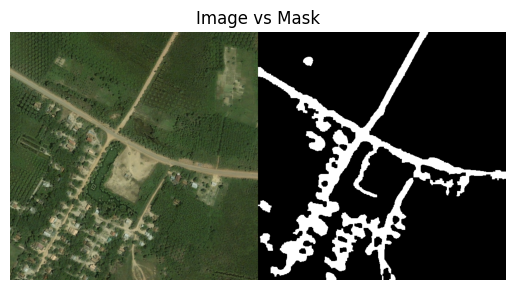

In [15]:
mask_vis = (morph_mask * 255).astype(np.uint8)   # scale to 0–255
mask_vis = cv2.cvtColor(mask_vis, cv2.COLOR_GRAY2BGR)  # make 3-channel

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

combined = cv2.hconcat([img_rgb, mask_vis])

plt.imshow(combined)
plt.title('Image vs Mask')
plt.axis('off')
plt.show()

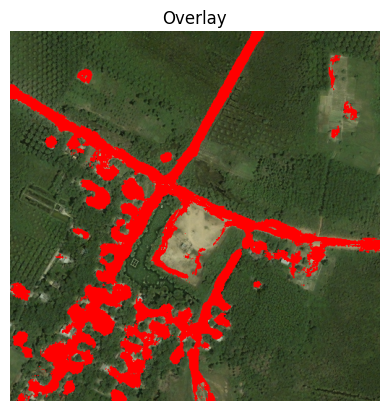

In [16]:
overlay = img_rgb.copy()
overlay[mask == 1] = [255, 0, 0]  # highlight roads in red

plt.imshow(overlay)
plt.title('Overlay')
plt.axis('off')
plt.show()

Components kept: 2


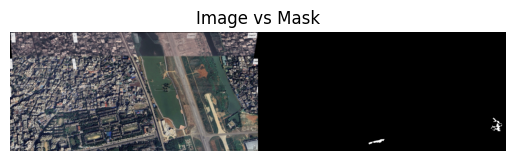

In [17]:
img = cv2.imread("topdown_image.png")
mask = predict_image(rf, img)
morph_mask = post_process(mask)

mask_vis = (morph_mask * 255).astype(np.uint8)   # scale to 0–255
mask_vis = cv2.cvtColor(mask_vis, cv2.COLOR_GRAY2BGR)  # make 3-channel

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

combined = cv2.hconcat([img_rgb, mask_vis])

plt.imshow(combined)
plt.title('Image vs Mask')
plt.axis('off')
plt.show()

## Results: 
* With just 6 hsv features(mean and std):     
precision    recall  f1-score   support

    Non-road       0.74      0.86      0.80     17241   
        Road       0.88      0.77      0.82     22759   
                                                            
    accuracy                           0.81     40000   
   macro avg       0.81      0.82      0.81     40000   
weighted avg       0.82      0.81      0.81     40000   

* hsv + lbp:   
precision    recall  f1-score   support 

    Non-road       0.71      0.84      0.77     17037   
        Road       0.86      0.75      0.80     22963   

    accuracy                           0.78     40000   
   macro avg       0.78      0.79      0.78     40000   
weighted avg       0.80      0.78      0.79     40000   

* With hsv + lbp + sobel    
precision    recall  f1-score   support 

    Non-road       0.73      0.85      0.79     17320   
        Road       0.87      0.76      0.81     22680   

    accuracy                           0.80     40000   
   macro avg       0.80      0.81      0.80     40000   
weighted avg       0.81      0.80      0.80     40000  

* With streamlined pipeline:        
precision    recall  f1-score   support 

    Non-road       0.82      0.93      0.87     17617   
        Road       0.94      0.84      0.89     22383   

    accuracy                           0.88     40000   
   macro avg       0.88      0.89      0.88     40000   
weighted avg       0.89      0.88      0.88     40000   